# Damping spectrum: overdamped ↔ underdamped

Relaxation of the integral-feedback system back to its set point, using the dimensionless model from `02-optimal-control-proper-time.ipynb`:

$$\dot{A} = t_r\, q\,(1 - B), \qquad \dot{B} = t_r\,(uA - B)$$

With constant $u=1$, $B$ obeys $\ddot{B} + t_r\dot{B} + t_r^2 q\,(B-1) = 0$, so the damping ratio is $\zeta = 1/(2\sqrt{q})$:
$q<1/4$ is overdamped and $q>1/4$ is underdamped. $t_r(q)$ rescales time so the slowest decay rate is 1 for every $q$.

Start from a displaced steady state, $A_0 = B_0 = 1+\delta$, so $\dot{B}(0)=0$ and $B$ relaxes to $B_{st}=1$ (dashed line).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [9]:
def t_relax(q):
    if q > 1/4:
        return 2
    else:
        return 2/(1-np.sqrt(1-4*q))

def f_state(t, x, q, u=1.0):
    A, B = x
    tr = t_relax(q)

    dA = tr*q*(1 - B)
    dB = tr*(u*A - B)

    return dA, dB

def simulate(q, delta=1.0, T=3.0, n=1000):
    x0 = [1 + delta, 1 + delta]
    t = np.linspace(0, T, n)
    sol = solve_ivp(f_state, (0, T), x0, args=(q,), t_eval=t, rtol=1e-9, atol=1e-11)
    return sol.t, sol.y[1]

def draw_axes(ax, t, B, color='k', lw=3.5):
    """Schematic axes: arrowed y-axis and a dashed, arrowed steady-state line as the time axis."""
    T = t[-1]
    ylo, yhi = min(B.min(), 1) - 0.25, B.max() + 0.35
    arrow = dict(arrowstyle='-|>', color='k', lw=1.2, mutation_scale=15)
    ax.annotate('', xy=(0, yhi), xytext=(0, ylo), arrowprops=arrow)
    ax.annotate('', xy=(1.1*T, 1), xytext=(0, 1),
                arrowprops=dict(arrow, color='0.3', linestyle=(0, (4, 3))))
    ax.plot(t, B, color=color, lw=lw, solid_capstyle='round')
    ax.set_xlim(-0.02*T, 1.12*T)
    ax.set_ylim(ylo, yhi)
    ax.axis('off')

## Two extremes

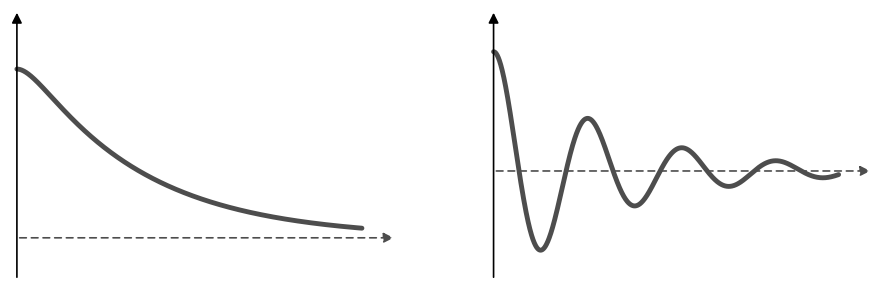

In [12]:
q_over = 0.1    # zeta ~ 1.6
q_under = 15    # zeta ~ 0.13

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, q in zip(axes, [q_over, q_under]):
    t, B = simulate(q)
    draw_axes(ax, t, B)
fig.tight_layout(w_pad=6)
fig.savefig('../plots/damping_spectrum.pdf', bbox_inches='tight')
plt.show()

## Spectrum across $q$

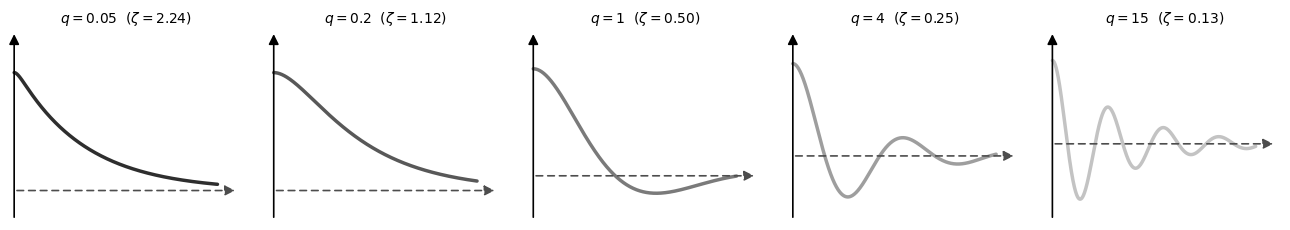

In [4]:
qs = [0.05, 0.2, 1, 4, 15]

fig, axes = plt.subplots(1, len(qs), figsize=(13, 2.4))
for ax, q in zip(axes, qs):
    t, B = simulate(q)
    draw_axes(ax, t, B)
    zeta = 1/(2*np.sqrt(q))
    ax.set_title(rf'$q={q:g}$  ($\zeta={zeta:.2f}$)', fontsize=10)
fig.tight_layout(w_pad=2)
# fig.savefig('damping_spectrum_strip.pdf', bbox_inches='tight')
plt.show()

## Growth functions $g(z)$: $c_1 - c_1 z$, $c_1 - c_2(-z)^+$, $c_1 - c_2 z^2$

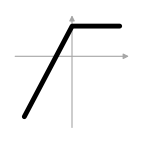

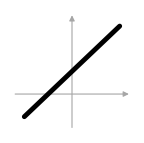

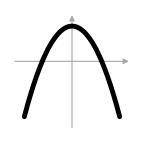

In [40]:
c1, c2 = 2, 1
mu = 0.0
zmax = 3
z = np.linspace(-zmax, zmax, 400)
g_funcs = {
    'relu': 1 - c2*np.maximum(mu - z, 0),
    'linear': 3 - c1*(mu - z),
    'quadratic': 3.5 - c2*(mu - z)**2,
}

arrow = dict(arrowstyle='-|>', color='0.65', lw=0.8, mutation_scale=8)
for name, g in g_funcs.items():
    ylo, yhi = min(g.min(), 0), max(g.max(), 0)
    pad_x, pad_y = 0.25*zmax, 0.15*(yhi - ylo)
    fig, ax = plt.subplots(figsize=(1.6, 1.6))
    ax.annotate('', xy=(zmax + pad_x, 0), xytext=(-zmax - pad_x, 0), arrowprops=arrow)
    ax.annotate('', xy=(0, yhi + pad_y), xytext=(0, ylo - pad_y), arrowprops=arrow)
    ax.plot(z, g, color='k', lw=3.5, solid_capstyle='round', zorder=4)
    ax.set_xlim(-zmax - 1.2*pad_x, zmax + 1.2*pad_x)
    ax.set_ylim(ylo - 1.2*pad_y, yhi + 1.2*pad_y)
    ax.axis('off')
    fig.savefig(f'../plots/g_{name}.pdf', bbox_inches='tight')
    plt.show()